# GTA Tactics — analisi del colpo

Questo notebook gioca migliaia di colpi con il motore di `colpo.py` e risponde a cinque domande che a mano non si misurano:

1. Un piano dà esiti sfumati o solo "riuscito / fallito"?
2. Esiste un piano che vince sempre?
3. I piani B scattano? Spostano il risultato?
4. Il sopralluogo ripaga il punto che costa?
5. Quanto del risultato dipende dal piano e quanto dalla sorte?

Tutto si misura sul **conto finale** in migliaia di euro. Il giocatore automatico non dà ordini dal vivo: fa solo ripetere le prove fallite di sala, uscita e fuga, finché ha interventi.

Se cambi un numero nel blocco `TARATURA` di `colpo.py`, riesegui tutto dall'inizio (Kernel → Restart & Run All). Ci mette circa un minuto.

In [1]:
import collections, itertools, random, statistics as st
import pandas as pd
import matplotlib.pyplot as plt
import colpo as C

BLU, INCHIOSTRO, GRIGIO = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "text.color": INCHIOSTRO, "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.options.display.max_colwidth = 120
ISTINTO = C.Istinto()

def scenario_a_caso(r, fisso=None):
    fatti = {f: r.choices([v[0] for v in vals], [v[1] for v in vals])[0] for f, (_, vals) in C.FATTI.items()}
    fatti.update(fisso or {})
    forma = {p: r.choices(list(C.FORMA_PESI), list(C.FORMA_PESI.values()))[0] for p in C.PERSONAGGI}
    return C.Scenario(0, fatti, forma)

def gioca_tanti(piano, scenari, r):
    return [C.gioca(s, piano, r.random(), ISTINTO) for s in scenari]

def media(esiti):
    return st.mean(e.conto for e in esiti)

def piani_base(budget=C.BUDGET):
    """Tutti i piani senza sopralluogo e senza piani B: banda x attrezzi x battute."""
    return [C.Piano(s, c, v, eq, frozenset(), b, {})
            for s, c, v in itertools.permutations(C.PERSONAGGI, 3)
            for eq in C.combinazioni_equip(budget) for b in (1, 2, 3)]

def con_piani_b(p, pb):
    return C.Piano(p.sala, p.cassaforte, p.volante, p.equip, p.sopralluoghi, p.battute, dict(pb))

def etichetta(p):
    return (f"{p.sala}/{p.cassaforte}/{p.volante} · {'+'.join(sorted(p.equip)) or 'niente'} · {p.battute} batt.")

def barre(ax, etichette, valori, titolo, fmt="{:.0%}"):
    y = range(len(etichette))
    ax.barh(list(y), valori, height=0.55, color=BLU)
    ax.set_yticks(list(y)); ax.set_yticklabels(etichette); ax.invert_yaxis()
    ax.set_title(titolo); ax.grid(axis="y", visible=False); ax.tick_params(length=0)
    largo = max(max(valori), 1e-9)
    for i, v in enumerate(valori):
        ax.text(v + largo * 0.02, i, fmt.format(v), va="center", color=INCHIOSTRO, fontsize=9)
    ax.set_xlim(min(0, min(valori)), largo * 1.18); ax.set_xticklabels([])

## 1. Un piano, mille colpi

Scrivi qui sotto il piano che vuoi mettere alla prova. I nomi validi sono quelli stampati dalla cella.

**Cosa cercare:** una distribuzione larga, con il grosso sui colpi "riusciti a metà" o "sporchi". Se quasi tutto cade su un solo verdetto, il colpo è binario.

Personaggi: nico, vera, tony, samir, lea
Attrezzi:   silenziata, fucile, disturbatore, trapano, auto, scanner
Condizioni: allarme, guardia, ferito, sirene | risposte: fuori, ostaggio, lascia, continua


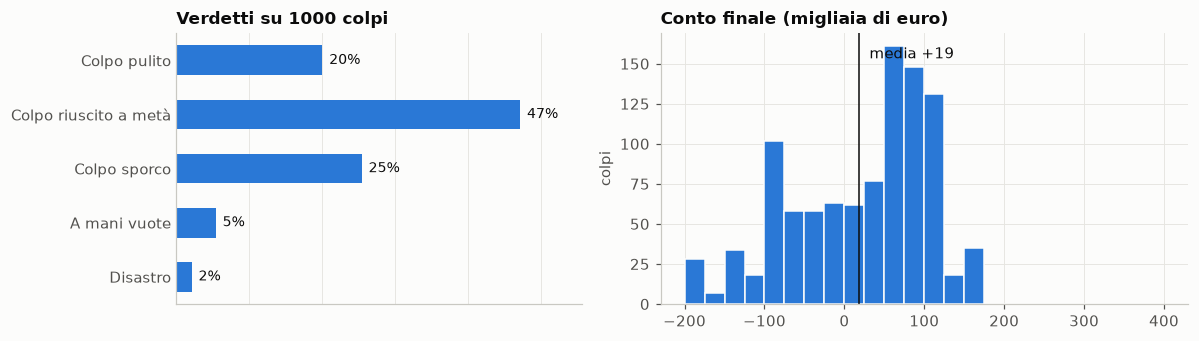

Conto medio +19 mila · in perdita 37% dei colpi · allarme 50% · calore medio 5.5


In [2]:
print("Personaggi:", ", ".join(C.PERSONAGGI))
print("Attrezzi:  ", ", ".join(C.EQUIP))
print("Condizioni:", ", ".join(C.CONDIZIONI), "| risposte:", ", ".join(C.RISPOSTE))

MIO_PIANO = C.Piano(
    sala="vera", cassaforte="lea", volante="samir",
    equip=frozenset({"silenziata", "scanner", "disturbatore"}),
    battute=2,
    piani_b={"allarme": "fuori", "guardia": "ostaggio"},
)
assert not MIO_PIANO.errori(), MIO_PIANO.errori()

r = random.Random(1)
esiti = gioca_tanti(MIO_PIANO, [scenario_a_caso(r) for _ in range(1000)], r)
ordine = ["COLPO PULITO", "COLPO RIUSCITO A METÀ", "COLPO SPORCO", "A MANI VUOTE", "DISASTRO"]
quote = collections.Counter(e.verdetto for e in esiti)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})
barre(a, [v.capitalize() for v in ordine], [quote[v] / len(esiti) for v in ordine], "Verdetti su 1000 colpi")
b.hist([e.conto for e in esiti], bins=range(-200, 401, 25), color=BLU, edgecolor="#fcfcfb", linewidth=1)
b.axvline(media(esiti), color=INCHIOSTRO, linewidth=1)
b.text(media(esiti), b.get_ylim()[1] * 0.95, f"  media {media(esiti):+.0f}", color=INCHIOSTRO, va="top")
b.set_title("Conto finale (migliaia di euro)"); b.set_ylabel("colpi")
plt.tight_layout(); plt.show()

print(f"Conto medio {media(esiti):+.0f} mila · in perdita {sum(e.conto < 0 for e in esiti)/len(esiti):.0%} dei colpi · "
      f"allarme {sum(e.allarme for e in esiti)/len(esiti):.0%} · calore medio {st.mean(e.calore for e in esiti):.1f}")

## 2. Esiste un piano che vince sempre?

Qui si provano **tutti** i piani base possibili (banda, attrezzi, battute; senza sopralluogo né piani B) su una gioielleria ogni volta diversa.

**Cosa cercare:**
- La curva in alto deve essere piatta: tanti piani a poca distanza dal migliore. Se il primo stacca gli altri, il colpo è un rompicapo con una soluzione.
- Nella composizione dei piani migliori nessuna voce dovrebbe stare vicino al 100% o allo 0%: una carta sempre presente è obbligata, una mai presente è morta.

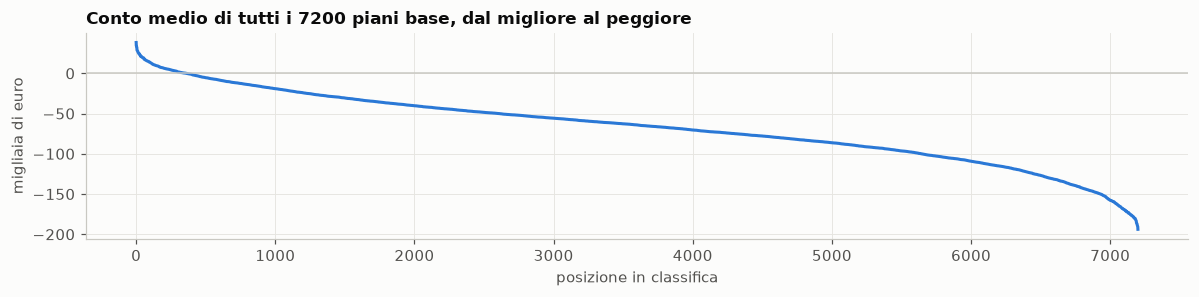

Miglior piano: +38 mila. Piani entro 10 mila dal migliore: 14.


,piano,conto medio,allarme,calore,pulito,a metà,sporco,disastro
0,tony/nico/samir · disturbatore+scanner+silenziata · 2 batt.,38,38%,3.6,61%,27%,5%,6%
1,tony/lea/samir · disturbatore+scanner+silenziata · 2 batt.,32,54%,5.0,21%,64%,7%,6%
2,tony/nico/lea · disturbatore+scanner+silenziata · 2 batt.,31,38%,4.5,35%,52%,5%,6%
3,tony/nico/samir · disturbatore+silenziata · 2 batt.,31,39%,3.9,59%,27%,6%,8%
4,tony/nico/samir · scanner+silenziata · 2 batt.,30,36%,3.8,61%,24%,5%,9%
5,tony/lea/samir · auto+silenziata+trapano · 2 batt.,30,93%,6.8,0%,51%,43%,5%
6,tony/nico/lea · auto+disturbatore+silenziata · 3 batt.,29,79%,6.4,1%,55%,40%,5%
7,tony/lea/samir · auto+scanner+silenziata · 2 batt.,29,48%,5.6,4%,71%,22%,2%
8,tony/nico/samir · auto+scanner+silenziata · 2 batt.,29,38%,4.3,36%,56%,6%,2%
9,tony/nico/samir · scanner+silenziata+trapano · 1 batt.,29,20%,2.9,18%,75%,2%,2%


In [3]:
r = random.Random(2)
scenari = [scenario_a_caso(r) for _ in range(60)]
BASI = piani_base()
classifica = sorted(((media(gioca_tanti(p, scenari, r)), p) for p in BASI), key=lambda x: -x[0])

# i 60 migliori rigiocati su 600 gioiellerie nuove: toglie il vantaggio di chi ha solo avuto fortuna
scenari2 = [scenario_a_caso(r) for _ in range(600)]
finalisti = sorted(((gioca_tanti(p, scenari2, r), p) for _, p in classifica[:60]), key=lambda x: -media(x[0]))

righe = []
for es, p in finalisti[:15]:
    q = collections.Counter(e.verdetto for e in es)
    righe.append({"piano": etichetta(p), "conto medio": round(media(es)),
                  "allarme": f"{sum(e.allarme for e in es)/len(es):.0%}",
                  "calore": round(st.mean(e.calore for e in es), 1),
                  "pulito": f"{q['COLPO PULITO']/len(es):.0%}", "a metà": f"{q['COLPO RIUSCITO A METÀ']/len(es):.0%}",
                  "sporco": f"{q['COLPO SPORCO']/len(es):.0%}", "disastro": f"{q['DISASTRO']/len(es):.0%}"})
tab_top = pd.DataFrame(righe)

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot([u for u, _ in classifica], color=BLU, linewidth=2)
ax.axhline(0, color="#c9c8c2", linewidth=1)
ax.set_title(f"Conto medio di tutti i {len(BASI)} piani base, dal migliore al peggiore")
ax.set_xlabel("posizione in classifica"); ax.set_ylabel("migliaia di euro")
plt.tight_layout(); plt.show()

migliore = media(finalisti[0][0])
vicini = sum(media(es) >= migliore - 10 for es, _ in finalisti)
print(f"Miglior piano: {migliore:+.0f} mila. Piani entro 10 mila dal migliore: {vicini}.")
tab_top

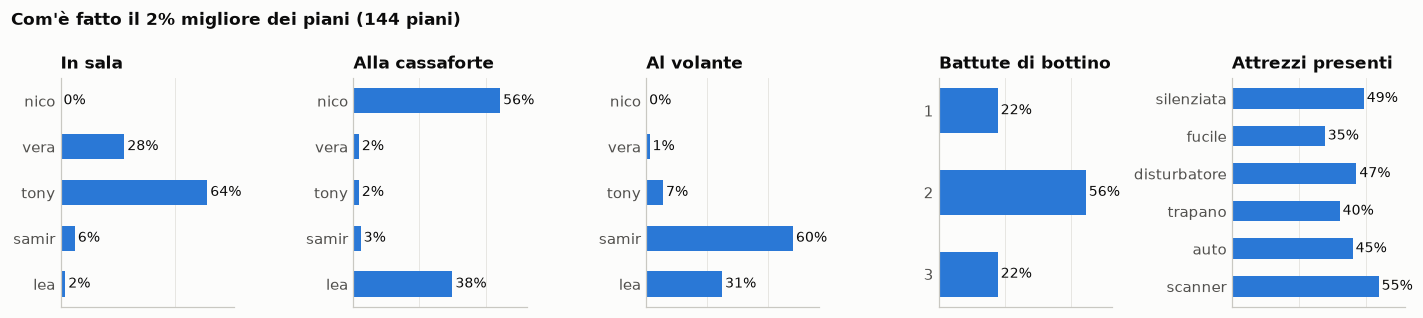

In [4]:
K = len(BASI) // 50   # il 2% migliore
top = [p for _, p in classifica[:K]]
quota = lambda f: collections.Counter(f(p) for p in top)

fig, axs = plt.subplots(1, 5, figsize=(13, 2.9))
for ax, (nome, f, chiavi) in zip(axs, [
        ("In sala", lambda p: p.sala, list(C.PERSONAGGI)),
        ("Alla cassaforte", lambda p: p.cassaforte, list(C.PERSONAGGI)),
        ("Al volante", lambda p: p.volante, list(C.PERSONAGGI)),
        ("Battute di bottino", lambda p: p.battute, [1, 2, 3])]):
    q = quota(f)
    barre(ax, [str(k) for k in chiavi], [q[k] / K for k in chiavi], nome)
barre(axs[4], list(C.EQUIP), [sum(e in p.equip for p in top) / K for e in C.EQUIP], "Attrezzi presenti")
fig.suptitle(f"Com'è fatto il 2% migliore dei piani ({K} piani)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

for nome, f, chiavi in [("sala", lambda p: p.sala, C.PERSONAGGI), ("cassaforte", lambda p: p.cassaforte, C.PERSONAGGI),
                        ("volante", lambda p: p.volante, C.PERSONAGGI)]:
    k, n = quota(f).most_common(1)[0]
    if n / K > 0.75:
        print(f"SEGNALE: {k} è {nome} nel {n/K:.0%} dei piani migliori. Scelta quasi obbligata.")
for e in C.EQUIP:
    q = sum(e in p.equip for p in top) / K
    if q < 0.10: print(f"SEGNALE: «{e}» compare solo nel {q:.0%} dei piani migliori. Carta quasi morta.")
    if q > 0.85: print(f"SEGNALE: «{e}» compare nel {q:.0%} dei piani migliori. Carta quasi obbligata.")

## 3. I piani B scattano? Spostano il risultato?

Prima tabella: quanto spesso scatta ogni condizione, giocando i 15 piani migliori senza piani B.
Seconda tabella: per i 5 piani migliori si provano tutte le 67 combinazioni di piani B.

**Cosa cercare:** condizioni che scattano né mai né sempre, e una differenza visibile tra la combinazione migliore, nessun piano B e la peggiore. Se la migliore è sempre la stessa, la scelta dei piani B è finta.

In [5]:
r = random.Random(3)
sc = [scenario_a_caso(r) for _ in range(400)]
tutti = [e for es, p in finalisti[:15] for e in gioca_tanti(p, sc, r)]
freq = pd.DataFrame([{"condizione": C.CONDIZIONI[c],
                      "scatta nel": f"{sum(c in e.condizioni for e in tutti)/len(tutti):.0%} dei colpi"} for c in C.CONDIZIONI])
print(f"Panico (condizione scattata senza piano B, nervi saltati): {sum(e.panici > 0 for e in tutti)/len(tutti):.0%} dei colpi")
display(freq)
for c in C.CONDIZIONI:
    q = sum(c in e.condizioni for e in tutti) / len(tutti)
    if q < 0.05: print(f"SEGNALE: «{C.CONDIZIONI[c]}» scatta solo nel {q:.0%} dei colpi. Un piano B messo lì non scatta quasi mai.")
    if q > 0.80: print(f"SEGNALE: «{C.CONDIZIONI[c]}» scatta nel {q:.0%} dei colpi. Non è un imprevisto, è la norma.")

PB = C.combinazioni_piani_b()
dici = lambda pb: ", ".join(f"{c}→{x}" for c, x in pb.items()) or "nessuno"
righe, vincenti = [], collections.Counter()
for es, p in finalisti[:5]:
    ris = sorted(((media(gioca_tanti(con_piani_b(p, pb), sc, r)), pb) for pb in PB), key=lambda x: -x[0])
    nessuno = next(u for u, pb in ris if not pb)
    for u, pb in ris[:5]:
        for c, x in pb.items(): vincenti[f"{c}→{x}"] += 1
    righe.append({"piano": etichetta(p), "migliori piani B": dici(ris[0][1]), "conto": round(ris[0][0]),
                  "senza piani B": round(nessuno), "peggiori piani B": dici(ris[-1][1]), "conto ": round(ris[-1][0])})
display(pd.DataFrame(righe))
print("Le risposte più presenti nelle 5 combinazioni migliori di ogni piano:",
      ", ".join(f"{k} ({v})" for k, v in vincenti.most_common(6)))

Panico (condizione scattata senza piano B, nervi saltati): 12% dei colpi


,condizione,scatta nel
0,scatta l'allarme,37% dei colpi
1,la guardia reagisce,3% dei colpi
2,un uomo è ferito,2% dei colpi
3,si sentono le sirene (polizia a una battuta),10% dei colpi


SEGNALE: «la guardia reagisce» scatta solo nel 3% dei colpi. Un piano B messo lì non scatta quasi mai.
SEGNALE: «un uomo è ferito» scatta solo nel 2% dei colpi. Un piano B messo lì non scatta quasi mai.


,piano,migliori piani B,conto,senza piani B,peggiori piani B,conto
0,tony/nico/samir · disturbatore+scanner+silenziata · 2 batt.,"allarme→fuori, guardia→continua",52,41,"allarme→ostaggio, guardia→fuori",27
1,tony/lea/samir · disturbatore+scanner+silenziata · 2 batt.,guardia→continua,45,37,"allarme→ostaggio, guardia→ostaggio",17
2,tony/nico/lea · disturbatore+scanner+silenziata · 2 batt.,"allarme→continua, guardia→fuori",44,35,"allarme→ostaggio, sirene→ostaggio",23
3,tony/nico/samir · disturbatore+silenziata · 2 batt.,"ferito→continua, sirene→ostaggio",47,33,"allarme→ostaggio, sirene→continua",22
4,tony/nico/samir · scanner+silenziata · 2 batt.,"guardia→fuori, sirene→ostaggio",45,33,"allarme→ostaggio, sirene→fuori",24


Le risposte più presenti nelle 5 combinazioni migliori di ogni piano: allarme→fuori (7), guardia→fuori (7), allarme→continua (6), sirene→ostaggio (5), guardia→continua (4), ferito→fuori (4)


## 4. Il sopralluogo ripaga?

Verificare un fatto costa 1 punto, cioè attrezzi in meno. Per ogni fatto si confronta:

- **al buio**: il miglior piano da 6 punti, scelto senza sapere niente;
- **informato**: il miglior piano da 5 punti, scelto sapendo quel fatto.

**Cosa cercare:** barre sopra lo zero. Una barra a zero o sotto dice che quel fatto non vale il punto: si va al buio senza rimpianti e la scelta sparisce.
I numeri hanno un margine di qualche migliaio di euro: differenze sotto i 5 mila sono rumore.

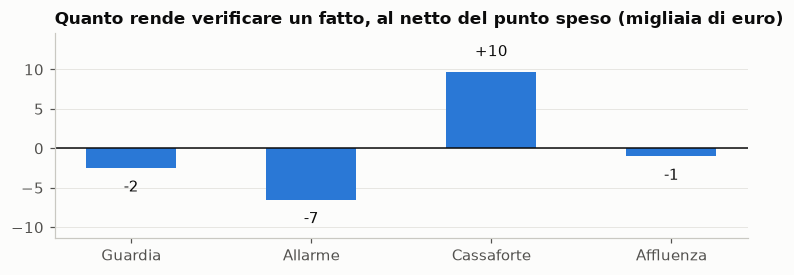

Piano al buio di riferimento: tony/nico/samir · disturbatore+scanner+silenziata · 2 batt.
SEGNALE: verificare «Guardia» rende -2 mila. Non ripaga il punto che costa.
SEGNALE: verificare «Allarme» rende -7 mila. Non ripaga il punto che costa.
SEGNALE: verificare «Affluenza» rende -1 mila. Non ripaga il punto che costa.


,fatto,valore,piano scelto sapendolo (5 punti),informato,al buio
0,Guardia,assente,tony/nico/samir · scanner+silenziata · 2 batt.,35,40
1,Guardia,anziana,tony/nico/samir · scanner+silenziata · 2 batt.,41,45
2,Guardia,armata,tony/nico/samir · disturbatore+fucile+scanner · 2 batt.,24,20
3,Allarme,sirena,tony/nico/lea · auto+scanner+silenziata · 3 batt.,34,37
4,Allarme,centrale,tony/nico/lea · disturbatore+scanner+silenziata · 2 batt.,36,41
5,Allarme,silenzioso,tony/nico/lea · disturbatore+scanner+silenziata · 2 batt.,30,41
6,Cassaforte,vecchia,tony/nico/samir · disturbatore+scanner+silenziata · 2 batt.,66,59
7,Cassaforte,moderna,tony/nico/samir · scanner+silenziata+trapano · 1 batt.,29,10
8,Cassaforte,a tempo,tony/lea/samir · scanner+silenziata+trapano · 1 batt.,35,34
9,Affluenza,vuoto,vera/nico/samir · scanner+silenziata · 2 batt.,58,58


In [6]:
r = random.Random(4)
cieco_p = finalisti[0][1]
candidati5 = [p for _, p in classifica if p.costo() <= C.BUDGET - C.COSTO_SOPRALLUOGO][:400]
righe, guadagni = [], {}
for f, (nome, valori) in C.FATTI.items():
    tot_inf = tot_buio = 0
    for v, peso, _ in valori:
        prova1 = [scenario_a_caso(r, {f: v}) for _ in range(150)]
        otto = sorted(candidati5, key=lambda p: -media(gioca_tanti(p, prova1, r)))[:8]
        prova2 = [scenario_a_caso(r, {f: v}) for _ in range(300)]       # scelta
        scelto = max(otto, key=lambda p: media(gioca_tanti(p, prova2, r)))
        prova3 = [scenario_a_caso(r, {f: v}) for _ in range(600)]       # misura, su colpi nuovi
        inf, buio = media(gioca_tanti(scelto, prova3, r)), media(gioca_tanti(cieco_p, prova3, r))
        tot_inf += peso / 100 * inf; tot_buio += peso / 100 * buio
        righe.append({"fatto": nome, "valore": v, "piano scelto sapendolo (5 punti)": etichetta(scelto),
                      "informato": round(inf), "al buio": round(buio)})
    guadagni[nome] = tot_inf - tot_buio

fig, ax = plt.subplots(figsize=(7, 2.6))
nomi = list(guadagni); vals = [guadagni[n] for n in nomi]
ax.bar(nomi, vals, width=0.5, color=BLU); ax.axhline(0, color=INCHIOSTRO, linewidth=1)
for i, v in enumerate(vals):
    ax.text(i, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f}", ha="center", va="bottom" if v >= 0 else "top", color=INCHIOSTRO)
ax.set_title("Quanto rende verificare un fatto, al netto del punto speso (migliaia di euro)")
ax.grid(axis="x", visible=False); ax.margins(y=0.3)
plt.tight_layout(); plt.show()
print(f"Piano al buio di riferimento: {etichetta(cieco_p)}")
for n, v in guadagni.items():
    if v < 5: print(f"SEGNALE: verificare «{n}» rende {v:+.0f} mila. Non ripaga il punto che costa.")
pd.DataFrame(righe)

## 5. Piano o sorte?

Si prendono 300 piani dalla metà migliore della classifica, 40 gioiellerie, e si gioca ogni coppia 4 volte con mazzo e dadi diversi. Poi si divide la variabilità del conto finale in tre parti:

- **piano**: quanto cambia il risultato medio da un piano all'altro;
- **gioielleria**: quanto pesano fatti nascosti e forma del giorno;
- **sorte**: mazzo e dadi, a parità di tutto il resto.

**Cosa cercare:** la sorte peserà sempre molto in un colpo singolo, ed è giusto così. Il segnale è la quota del piano: se è vicina a zero, scegliere bene o male non cambia niente. Conta anche il confronto finale tra piani buoni e piani presi a caso.

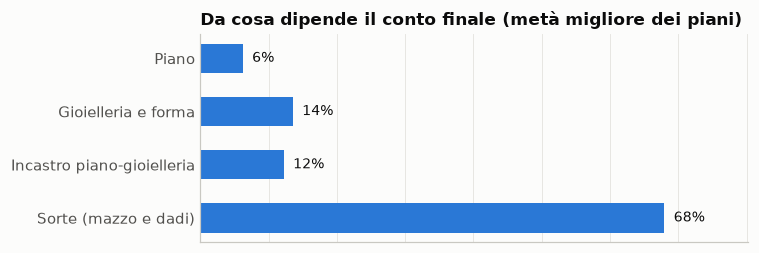

Piano preso a caso: -67 mila di media. Piano tra i migliori: +38 mila. Scegliere bene vale 105 mila a colpo.
Scarto tipico di un singolo colpo per sola sorte: ±77 mila.


In [7]:
r = random.Random(5)
campione = r.sample([p for _, p in classifica[:len(classifica) // 2]], 300)
sc5 = [scenario_a_caso(r) for _ in range(40)]
RIP = 4
dati = {(i, j): [C.gioca(s, p, r.random(), ISTINTO).conto for _ in range(RIP)]
        for i, p in enumerate(campione) for j, s in enumerate(sc5)}
tutti_v = [x for v in dati.values() for x in v]
var_tot = st.pvariance(tutti_v)
var_sorte = st.mean(st.variance(v) for v in dati.values())
medie_piano = [st.mean(x for j in range(len(sc5)) for x in dati[i, j]) for i in range(len(campione))]
medie_scen = [st.mean(x for i in range(len(campione)) for x in dati[i, j]) for j in range(len(sc5))]
parti = {"Piano": st.pvariance(medie_piano), "Gioielleria e forma": st.pvariance(medie_scen)}
parti["Incastro piano-gioielleria"] = max(0.0, var_tot - var_sorte - sum(parti.values()))
parti["Sorte (mazzo e dadi)"] = var_sorte

fig, ax = plt.subplots(figsize=(7, 2.4))
barre(ax, list(parti), [v / var_tot for v in parti.values()], "Da cosa dipende il conto finale (metà migliore dei piani)")
plt.tight_layout(); plt.show()

a_caso = st.mean(u for u, _ in classifica)
print(f"Piano preso a caso: {a_caso:+.0f} mila di media. Piano tra i migliori: {migliore:+.0f} mila. "
      f"Scegliere bene vale {migliore - a_caso:.0f} mila a colpo.")
print(f"Scarto tipico di un singolo colpo per sola sorte: ±{var_sorte ** 0.5:.0f} mila.")

## Come usare questi numeri

Le simulazioni dicono se le regole **possono** reggere: niente piano obbligato, piani B che contano, sopralluogo che ripaga, scelte che pesano più del caso nel lungo periodo.

Non dicono se il colpo **diverte**. Tensione mentre guardi, voglia di rigiocare e voglia di raccontarlo si misurano solo giocando, e le partite salvate in `partite/` sono la prova che conta.